# Content

The goal of this Notebook is to test logistic regression on the data. It also aims at testing such regression roughly on categorical data, to assess whether further steps are necessary. 

# Imports

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd
from sklearn.metrics import confusion_matrix
import seaborn as sns
import statsmodels.formula.api as smf
import sklearn

# 1-Opening data

#### a-Opening and cleaning

In [2]:
#Train
#Read input 
x_train_df = pd.read_csv('x_train.csv', sep=',')
print("Read x train: OK")

#Read output
y_train_df = pd.read_csv('y_train.csv', sep=',')
print("Read y train: OK")

#Clean inputs
x_train_df_clean = x_train_df.dropna(axis = 1, how='any').dropna(how="any")

#Clean outputs
y_train_df_clean = y_train_df.dropna(how='all')

#Test
x_test_df = pd.read_csv('x_test.csv', sep=',')
print("Read x test: OK")

#Clean test
x_test_df_clean = x_test_df.dropna(axis = 1, how='any').dropna(how="any")

Read x train: OK
Read y train: OK
Read x test: OK


In [4]:
x_train_df

,Id,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,...,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3
0,0,53,11,11162015,11,16,2015,1100,2015015629,2015015629,...,1,1,3.0,3.0,4.0,1,1,NaN,NaN,2.0
1,1,33,12,12152015,12,15,2015,1200,2015004387,2015004387,...,9,9,3.0,3.0,4.0,9,9,NaN,NaN,NaN
2,2,20,10,10202015,10,20,2015,1100,2015005638,2015005638,...,4,2,2.0,2.0,3.0,1,1,1.0,2.0,2.0
3,3,42,6,6182015,6,18,2015,1100,2015004694,2015004694,...,2,2,2.0,2.0,3.0,1,1,2.0,2.0,2.0
4,4,24,11,11062015,11,6,2015,1100,2015004673,2015004673,...,9,9,3.0,3.0,4.0,1,1,9.0,9.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328130,328130,49,7,11232015,11,23,2015,1100,2015006796,2015006796,...,2,2,3.0,3.0,4.0,1,1,NaN,NaN,2.0
328131,328131,51,5,6082015,6,8,2015,1100,2015006482,2015006482,...,1,1,3.0,3.0,4.0,1,1,NaN,NaN,1.0
328132,328132,39,10,10202015,10,20,2015,1100,2015004898,2015004898,...,3,2,3.0,3.0,4.0,1,2,2.0,2.0,2.0
328133,328133,33,12,12302015,12,30,2015,1100,2015004449,2015004449,...,3,2,3.0,3.0,4.0,1,1,NaN,NaN,2.0


#### b-Selecting most useful features

In [116]:
#Health features
L_interest_health = ['MENTHLTH', 'HLTHPLN1',
       'PERSDOC2', 'BLOODCHO', 'CVDSTRK3', 'ASTHMA3', 'CHCOCNCR', 'CHCCOPD1',
       'ADDEPEV2', 'CHCKIDNY', 'QSTVER', '_STSTR', '_RAWRAKE', '_WT2RAKE', '_DUALUSE',
       '_LLCPWT', '_RFHLTH', '_HCVU651', '_RFHYPE5', '_CHOLCHK', '_LTASTH1',
       '_CASTHM1', '_ASTHMS1', '_SMOKER3', '_RFSMOK3',
       'DRNKANY5', 'DROCDY3_', '_RFBING5', '_DRNKWEK', '_RFDRHV5', '_MISFRTN',
       '_MISVEGN', '_FRTRESP', '_VEGRESP', '_FRTLT1', '_VEGLT1', '_FRT16',
       '_VEG23', '_FRUITEX', '_VEGETEX', '_TOTINDA', 'MAXVO2_', 'FC60_',
       'PAMISS1_', '_PACAT1', '_PAINDX1', '_PA150R2', '_PA300R2', '_PA30021',
       '_PASTRNG', '_PAREC1', '_PASTAE1', '_RFSEAT2', '_RFSEAT3']

#Extended features
L_feature = ['MENTHLTH', 'HLTHPLN1',
       'PERSDOC2', 'BLOODCHO', 'CVDSTRK3', 'ASTHMA3', 'CHCOCNCR', 'CHCCOPD1',
       'ADDEPEV2', 'CHCKIDNY', 'SEX', 'MARITAL', 'EDUCA', 'RENTHOM1',
       'EMPLOY1', 'QSTVER', '_STSTR', '_RAWRAKE', '_WT2RAKE', '_DUALUSE',
       '_LLCPWT', '_RFHLTH', '_HCVU651', '_RFHYPE5', '_CHOLCHK', '_LTASTH1',
       '_CASTHM1', '_ASTHMS1', '_PRACE1', '_MRACE1', '_HISPANC', '_RACE',
       '_RACEG21', '_RACEGR3', '_AGEG5YR', '_AGE65YR', '_AGE80', '_AGE_G',
       '_RFBMI5', '_CHLDCNT', '_EDUCAG', '_INCOMG', '_SMOKER3', '_RFSMOK3',
       'DRNKANY5', 'DROCDY3_', '_RFBING5', '_DRNKWEK', '_RFDRHV5', '_MISFRTN',
       '_MISVEGN', '_FRTRESP', '_VEGRESP', '_FRTLT1', '_VEGLT1', '_FRT16',
       '_VEG23', '_FRUITEX', '_VEGETEX', '_TOTINDA', 'MAXVO2_', 'FC60_',
       'PAMISS1_', '_PACAT1', '_PAINDX1', '_PA150R2', '_PA300R2', '_PA30021',
       '_PASTRNG', '_PAREC1', '_PASTAE1', '_RFSEAT2', '_RFSEAT3']

#Health features
x_train_df_clean_health = x_train_df_clean[L_feature]

#Health outputs
y_train_df_clean_health = y_train_df_clean["_MICHD"]

# 2-Split train/validation datasets

In [117]:
#Dtype
dtype_array = np.float64

#Conversion to numpy
x_train_df_clean_health_array = x_train_df_clean_health.to_numpy(dtype=dtype_array)
y_train_df_clean_health_array = y_train_df_clean_health.to_numpy(dtype=dtype_array).reshape(-1,1)

#Mask definition
rng = np.random.default_rng()
n = len(y_train_df_clean_health_array)
ratio_mask = 33
mask = rng.random(n) >= ratio_mask / 100

#Train/validation split
x_tr = x_train_df_clean_health_array[mask]
y_tr = y_train_df_clean_health_array[mask]
x_te = x_train_df_clean_health_array[~mask]
y_te = y_train_df_clean_health_array[~mask]

#PCA
pca = sklearn.decomposition.PCA(n_components=60)
pca.fit(x_tr)
x_tr_pca = pca.transform(x_tr)
x_te_pca = pca.transform(x_te)

#Normalization
x_tr_norm = (x_tr - np.mean(x_tr)) / (np.std(x_tr))
y_tr_norm = (y_tr - np.mean(y_tr)) / (np.std(y_tr))
x_te_norm = (x_te - np.mean(x_te)) / (np.std(x_te))
y_te_norm = (y_te - np.mean(y_te)) / (np.std(y_te))

x_tr_pca_norm = (x_tr_pca - np.mean(x_tr_pca)) / (np.std(x_tr_pca))
x_te_pca_norm = (x_te_pca - np.mean(x_te_pca)) / (np.std(x_te_pca))

#Tx
tx_tr_norm = np.c_[np.ones((y_tr_norm.shape[0], 1)), x_tr_norm]
tx_tr_norm = tx_tr_norm.astype(dtype_array)
tx_te_norm = np.c_[np.ones((y_te_norm.shape[0], 1)), x_te_norm]
tx_te_norm = tx_te_norm.astype(dtype_array)

tx_tr_pca_norm = np.c_[np.ones((y_tr_norm.shape[0], 1)), x_tr_pca_norm]
tx_tr_pca_norm = tx_tr_pca_norm.astype(dtype_array)
tx_te_pca_norm = np.c_[np.ones((y_te_norm.shape[0], 1)), x_te_pca_norm]
tx_te_pca_norm = tx_te_pca_norm.astype(dtype_array)

# 3-Logistic regression

#### a-Training

In [118]:
def sigmoid(t):
    """apply sigmoid function on t.

    Args:
        t: scalar or numpy array

    Returns:
        scalar or numpy array
    """
    return(1/(1+np.exp(-t)))



def calculate_loss(y, tx, w):
    """compute the cost by negative log likelihood.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)

    Returns:
        a non-negative loss
    """
    assert y.shape[0] == tx.shape[0]
    assert tx.shape[1] == w.shape[0]

    N = len(y)
    loss = 1/N * np.sum(-y * (tx @ w) + np.logaddexp(0, tx @ w))
    return(loss)



def calculate_gradient(y, tx, w):
    """compute the gradient of loss.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)

    Returns:
        a vector of shape (D, 1)
    """
    N = len(y)
    gradient = 1/N * tx.T @ (sigmoid(tx @ w) - y)
    return(gradient)



def learning_by_gradient_descent(y, tx, w, gamma):
    """
    Do one step of gradient descent using logistic regression. Return the loss and the updated w.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)
        gamma: float

    Returns:
        loss: scalar number
        w: shape=(D, 1)
    """
    #Gradient
    gradient = calculate_gradient(y, tx, w)
    w_new = w - gamma * gradient
    loss = calculate_loss(y, tx, w)
    return(loss, w_new)

Current iteration=0, loss_train=0.6931471805599452, loss_test=0.5640518801714005
Current iteration=100, loss_train=0.0880043586989806, loss_test=0.08822155082571291
Current iteration=200, loss_train=0.06876386193670435, loss_test=0.06926300159579227
Current iteration=300, loss_train=0.06032653351553667, loss_test=0.06091118112362205
Current iteration=400, loss_train=0.055297592785188976, loss_test=0.055925077123117777


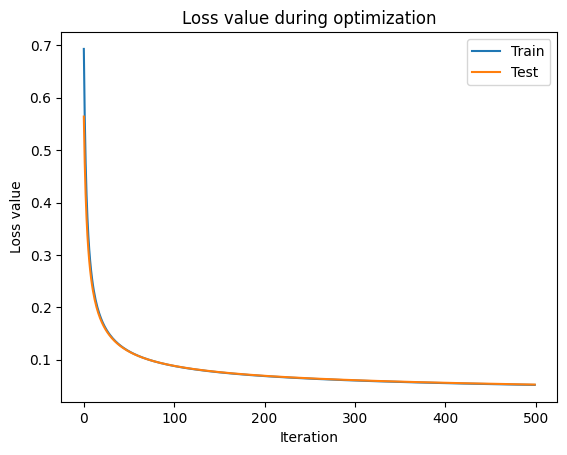

In [119]:
#Optimization
w = np.zeros((tx_tr_norm.shape[1], 1), dtype=dtype_array)
gamma = 0.01
losses_train = []
losses_test = []
max_iter = 500
for iter in range(max_iter):
    # get loss and update w.
    loss_train, w = learning_by_gradient_descent(y_tr_norm, tx_tr_norm, w, gamma)
    loss_test = calculate_loss(y_te_norm, tx_te_norm, w)
    # log info
    if iter % 100 == 0:
        print("Current iteration={i}, loss_train={l_tr}, loss_test={l_te}".format(i=iter, l_tr=loss_train, l_te=loss_test))
    # converge criterion
    losses_train.append(loss_train)
    losses_test.append(loss_test)

#Loss display
plt.plot(losses_train, label="Train")
plt.plot(losses_test, label="Test")
plt.ylabel("Loss value")
plt.xlabel("Iteration")
plt.title("Loss value during optimization")
plt.legend(loc="upper right")
plt.show()

#### b-Actual classification

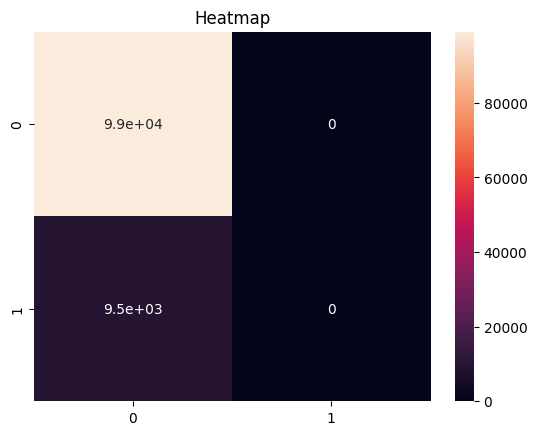

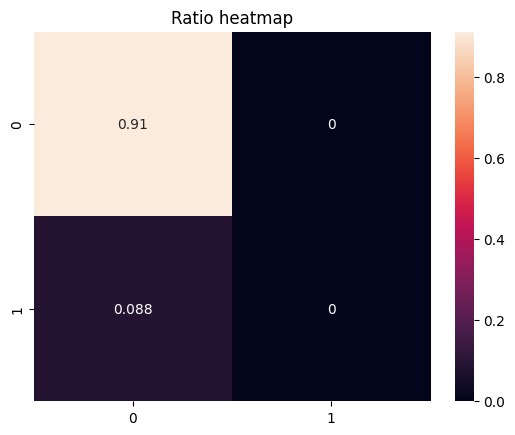

In [120]:
#Class choice
logistic_mask = sigmoid(tx_te_norm @ w) >= 0.5
y_te_pred = -1 * np.ones((np.shape(tx_te_norm)[0],1))
y_te_pred[logistic_mask] = 1

#Confusion matrix
cm = confusion_matrix(y_te, y_te_pred)

#Heatmap
sns.heatmap(cm, annot=True)
plt.title("Heatmap")
plt.show()

#Percentage confusion matrix
cm_ratio = cm/len(y_te)

#Heatmap
sns.heatmap(cm_ratio, annot=True)
plt.title("Ratio heatmap")
plt.show()

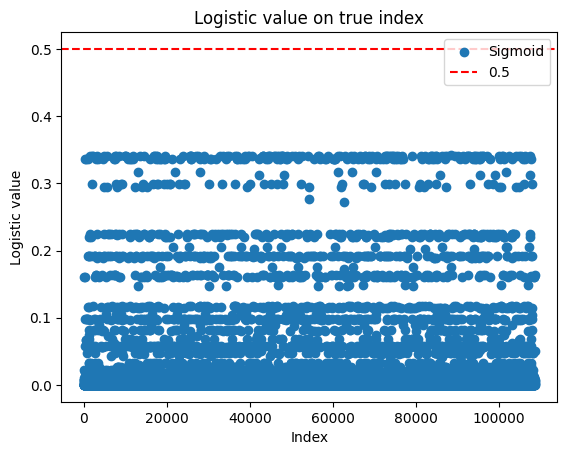

In [121]:
#Index of true true
index_true = np.where(y_te == 1)[0]

#Display
plt.scatter(index_true, sigmoid(tx_te_norm @ w)[index_true], label="Sigmoid")
plt.axhline(y=0.5, color='red', linestyle='--', label='0.5')
plt.xlabel("Index")
plt.ylabel("Logistic value")
plt.title("Logistic value on true index")
plt.legend()
plt.show()

# 4-Penalized logistic regression

#### a-Training

In [122]:
def logistic_regression(y, tx, w):
    """return the loss, gradient of the loss, and hessian of the loss.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)

    Returns:
        loss: scalar number
        gradient: shape=(D, 1)
        hessian: shape=(D, D)
    """
    gradient = calculate_gradient(y, tx, w)
    loss = calculate_loss(y, tx, w)
    return(loss, gradient)


def penalized_logistic_regression(y, tx, w, lambda_):
    """return the loss and gradient.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)
        lambda_: scalar

    Returns:
        loss: scalar number
        gradient: shape=(D, 1)
    """
    loss, gradient = logistic_regression(y, tx, w)

    #Penalization into account
    loss_penalized = loss + 1/2 * lambda_ * w.T @ w
    gradient_penalized = gradient + lambda_ * np.eye(len(w)) @ w
    return(loss_penalized, gradient_penalized)


def learning_by_penalized_gradient(y, tx, w, gamma, lambda_):
    """
    Do one step of gradient descent, using the penalized logistic regression.
    Return the loss and updated w.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)
        gamma: scalar
        lambda_: scalar

    Returns:
        loss: scalar number
        w: shape=(D, 1)
    """
    #Penalized loss and gradient
    loss, gradient = penalized_logistic_regression(y, tx, w, lambda_)

    #Update
    w_new = w - gamma * gradient
    return loss, w_new

Current iteration=0, loss_train=0.6931471805599452, loss_test=0.5640518801714005
Current iteration=100, loss_train=0.18091978207289144, loss_test=0.12132991827285261
Current iteration=200, loss_train=0.18012695657183223, loss_test=0.11559970188395895
Current iteration=300, loss_train=0.18002456561662472, loss_test=0.11469429878649476
Current iteration=400, loss_train=0.18000417634166654, loss_test=0.1144225110118197
Current iteration=500, loss_train=0.18000003508388365, loss_test=0.1143118973726943
Current iteration=600, loss_train=0.17999919331436656, loss_test=0.11426307277449299
Current iteration=700, loss_train=0.17999902220634267, loss_test=0.11424115196907426
Current iteration=800, loss_train=0.17999898742461184, loss_test=0.11423127701165577
Current iteration=900, loss_train=0.17999898035436207, loss_test=0.11422682556286547


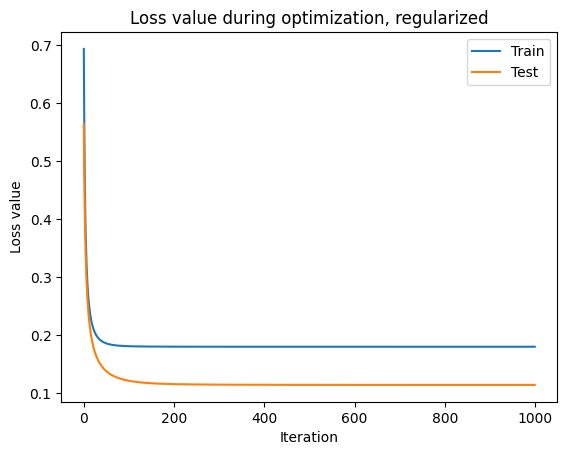

In [123]:
#Optimization
w = np.zeros((tx_tr_norm.shape[1], 1), dtype=dtype_array)
gamma = 0.01
lambda_ = 0.75
losses_train = []
losses_test = []
max_iter = 1000
for iter in range(max_iter):
    # get loss and update w.
    loss_train, w = learning_by_penalized_gradient(y_tr_norm, tx_tr_norm, w, gamma, lambda_)
    loss_test = calculate_loss(y_te_norm, tx_te_norm, w)
    # log info
    if iter % 100 == 0:
        print("Current iteration={i}, loss_train={l_tr}, loss_test={l_te}".format(i=iter, l_tr=loss_train[0][0], l_te=loss_test))
    # converge criterion
    losses_train.append(loss_train[0][0])
    losses_test.append(loss_test)

#Loss display
plt.plot(losses_train, label="Train")
plt.plot(losses_test, label="Test")
plt.ylabel("Loss value")
plt.xlabel("Iteration")
plt.title("Loss value during optimization, regularized")
plt.legend(loc="upper right")
plt.show()

#### b-Actual classification

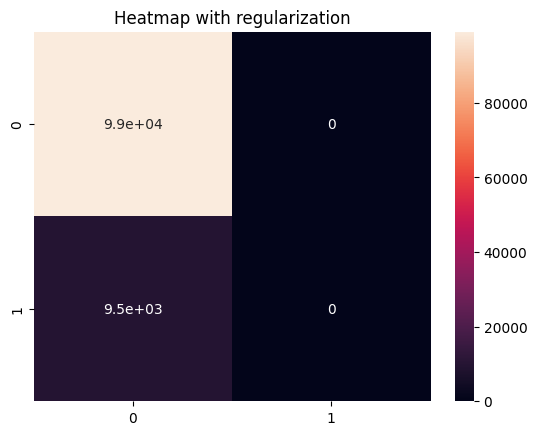

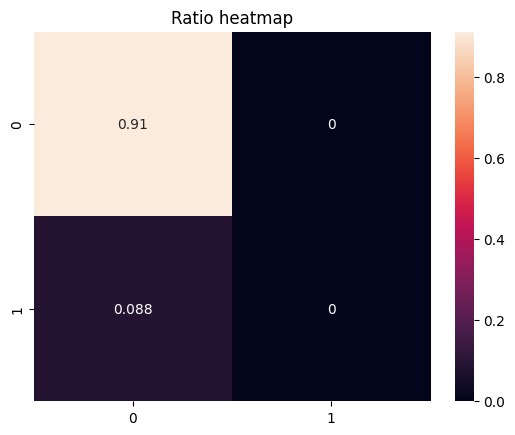

In [124]:
#Class choice
logistic_mask = sigmoid(tx_te_norm @ w) >= 0.5
y_te_pred = -1 * np.ones((np.shape(tx_te_norm)[0],1))
y_te_pred[logistic_mask] = 1

#Confusion matrix
cm = confusion_matrix(y_te, y_te_pred)

#Heatmap
sns.heatmap(cm, annot=True)
plt.title("Heatmap with regularization")
plt.show()

#Percentage confusion matrix
cm_ratio = cm/len(y_te)

#Heatmap
sns.heatmap(cm_ratio, annot=True)
plt.title("Ratio heatmap")
plt.show()

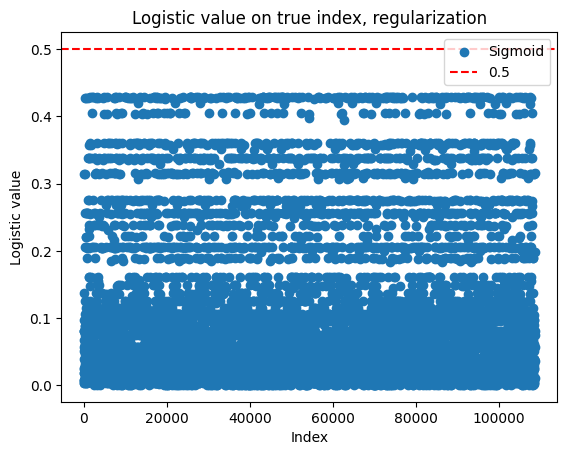

In [125]:
#Index of true true
index_true = np.where(y_te == 1)[0]

#Display
plt.scatter(index_true, sigmoid(tx_te_norm @ w)[index_true], label="Sigmoid")
plt.axhline(y=0.5, color='red', linestyle='--', label='0.5')
plt.xlabel("Index")
plt.ylabel("Logistic value")
plt.title("Logistic value on true index, regularization")
plt.legend()
plt.show()

# 5-Logistic regression with statsmodels

#### a-Training

In [126]:
#Extended features
L_feature = ['MENTHLTH', 'HLTHPLN1',
       'PERSDOC2', 'BLOODCHO', 'CVDSTRK3', 'ASTHMA3', 'CHCOCNCR', 'CHCCOPD1',
       'ADDEPEV2', 'CHCKIDNY', 'SEX', 'MARITAL', 'EDUCA', 'RENTHOM1',
       'EMPLOY1', 'QSTVER', '_STSTR', '_RAWRAKE', '_WT2RAKE', '_DUALUSE',
       '_LLCPWT', '_RFHLTH', '_HCVU651', '_RFHYPE5', '_CHOLCHK', '_LTASTH1',
       '_CASTHM1', '_ASTHMS1', '_PRACE1', '_MRACE1', '_HISPANC', '_RACE',
       '_RACEG21', '_RACEGR3', '_AGEG5YR', '_AGE65YR', '_AGE80', '_AGE_G',
       '_RFBMI5', '_CHLDCNT', '_EDUCAG', '_INCOMG', '_SMOKER3', '_RFSMOK3',
       'DRNKANY5', 'DROCDY3_', '_RFBING5', '_DRNKWEK', '_RFDRHV5', '_MISFRTN',
       '_MISVEGN', '_FRTRESP', '_VEGRESP', '_FRTLT1', '_VEGLT1', '_FRT16',
       '_VEG23', '_FRUITEX', '_VEGETEX', '_TOTINDA', 'MAXVO2_', 'FC60_',
       'PAMISS1_', '_PACAT1', '_PAINDX1', '_PA150R2', '_PA300R2', '_PA30021',
       '_PASTRNG', '_PAREC1', '_PASTAE1', '_RFSEAT2', '_RFSEAT3']

#Categorical features
categorical_features = [
    "HLTHPLN1", "PERSDOC2", "BLOODCHO", "CVDSTRK3",
    "ASTHMA3", "CHCOCNCR", "CHCCOPD1", "ADDEPEV2",
    "CHCKIDNY", "SEX", "MARITAL", "EDUCA", "RENTHOM1",
    "EMPLOY1", "QSTVER", "_RFHLTH", "_HCVU651",
    "_RFHYPE5", "_CHOLCHK", "_LTASTH1", "_CASTHM1",
    "_ASTHMS1", "_PRACE1", "_MRACE1", "_HISPANC",
    "_RACE", "_RACEG21", "_RACEGR3", "_AGEG5YR",
    "_AGE65YR", "_AGE_G", "_RFBMI5", "_CHLDCNT",
    "_EDUCAG", "_INCOMG", "_SMOKER3", "_RFSMOK3",
    "DRNKANY5", "_RFBING5", "_RFDRHV5", "_TOTINDA",
    "_PACAT1", "_PAINDX1", "_PA150R2", "_PA300R2",
    "_PA30021", "_PASTRNG", "_PAREC1", "_PASTAE1",
    "_RFSEAT2", "_RFSEAT3"
]

#Health features
x_train_df_clean_whole = x_train_df_clean[L_feature]

#Add output
x_train_df_clean_whole["_MICHD"] = y_train_df["_MICHD"]
x_train_df_clean_whole["_MICHD"] = (x_train_df_clean_whole["_MICHD"].map({-1: 0, 1: 1}))

#Transform into float32
x_train_df_clean_whole = x_train_df_clean_whole.astype(np.float32)

#Normalization
#x_train_df_clean_whole = (x_train_df_clean_whole - x_train_df_clean_whole.min())/(x_train_df_clean_whole.max() - x_train_df_clean_whole.min())

#Sampling
x_train_df_sample_tr = x_train_df_clean_whole.sample(frac=0.75, random_state=42)
x_train_df_sample_te = x_train_df_clean_whole.drop(x_train_df_sample_tr.index)

C:\Users\mayeu\AppData\Local\Temp\ipykernel_15696\3753280009.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x_train_df_clean_whole["_MICHD"] = y_train_df["_MICHD"]
C:\Users\mayeu\AppData\Local\Temp\ipykernel_15696\3753280009.py:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x_train_df_clean_whole["_MICHD"] = (x_train_df_clean_whole["_MICHD"].map({-1: 0, 1: 1}))


In [128]:
#Formula
formula = f"_MICHD ~ " + " + ".join(
    f'C({feature})' for feature in L_feature
)

# Les autres variables restent quantitatives
formula = "_MICHD ~ " + " + ".join(
    f'C({f})' if f in categorical_features
    else f'{f}'
    for f in L_feature
)

#Logistic regression
model = smf.logit(
    formula=formula,
    data=x_train_df_sample_tr
).fit(maxiter=25)

C:\Users\mayeu\AppData\Roaming\Python\Python313\site-packages\statsmodels\discrete\discrete_model.py:2385: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-X))
C:\Users\mayeu\AppData\Roaming\Python\Python313\site-packages\statsmodels\discrete\discrete_model.py:2443: RuntimeWarning: divide by zero encountered in log
  return np.sum(np.log(self.cdf(q * linpred)))


         Current function value: inf
         Iterations: 25


LinAlgError: Singular matrix

#### b-Actual classification

In [ ]:
#Class prediction
y_proba_statsmodels = model.predict(x_train_df_sample_te)
y_pred_statsmodels = (y_proba_statsmodels >= 0.5).astype(int)

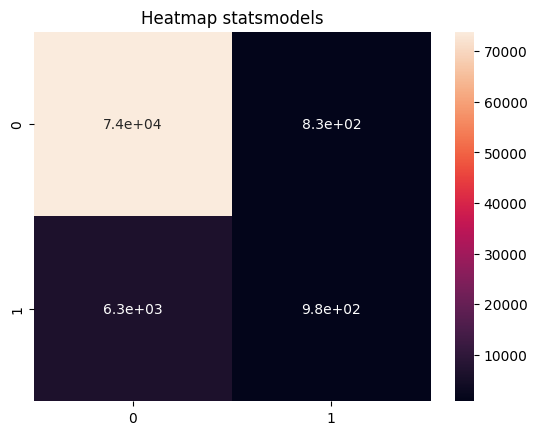

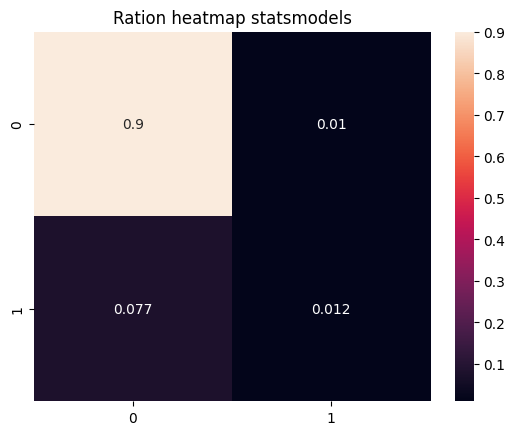

In [ ]:
#Confusion matrix
cm = confusion_matrix(x_train_df_sample_te["_MICHD"], y_pred_statsmodels)

#Heatmap
sns.heatmap(cm, annot=True)
plt.title("Heatmap statsmodels")
plt.show()

#Percentage confusion matrix
cm_ratio = cm/len(x_train_df_sample_te["_MICHD"])

#Heatmap
sns.heatmap(cm_ratio, annot=True)
plt.title("Ration heatmap statsmodels")
plt.show()

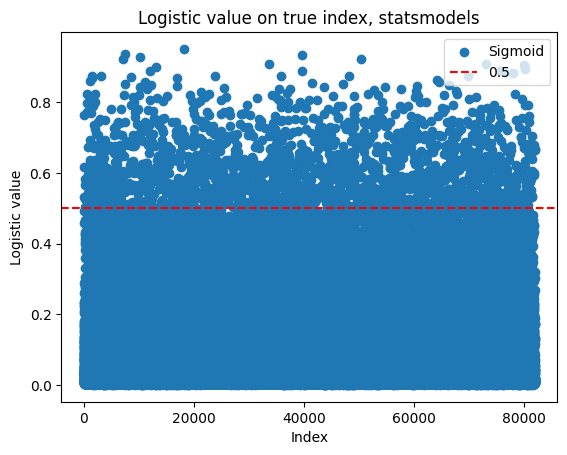

In [ ]:
#Display
plt.scatter(np.arange(len(y_proba_statsmodels)), y_proba_statsmodels, label="Sigmoid")
plt.axhline(y=0.5, color='red', linestyle='--', label='0.5')
plt.xlabel("Index")
plt.ylabel("Logistic value")
plt.title("Logistic value on true index, statsmodels")
plt.legend()
plt.show()

# 6-kNN

#### a-Training

In [146]:
#Fit
neigh = sklearn.neighbors.KNeighborsClassifier(n_neighbors=2)
neigh.fit(x_tr, y_tr.ravel())

#Predict
y_te_pred_kNN = neigh.predict(x_te)

#### b-Actual prediction

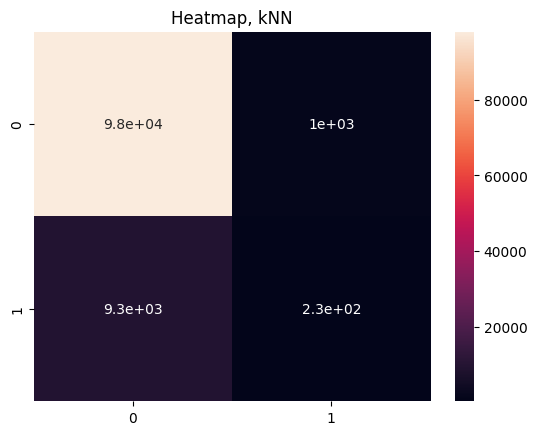

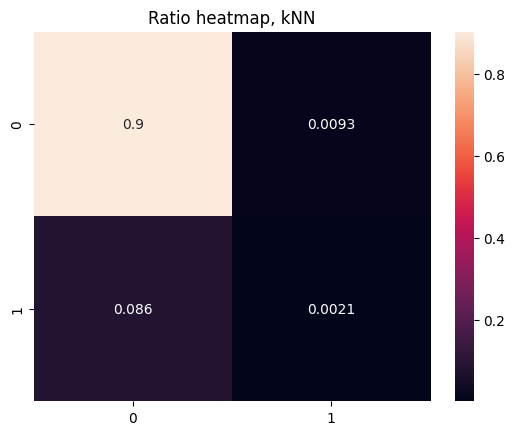

In [148]:
#Confusion matrix
cm = confusion_matrix(y_te, y_te_pred_kNN)

#Heatmap
sns.heatmap(cm, annot=True)
plt.title("Heatmap, kNN")
plt.show()

#Percentage confusion matrix
cm_ratio = cm/len(y_te)

#Heatmap
sns.heatmap(cm_ratio, annot=True)
plt.title("Ratio heatmap, kNN")
plt.show()

# 7-SVM

#### a-Training

In [150]:
#Fit
clf = sklearn.svm.SVC()
clf.fit(x_tr, y_tr.ravel())

#Predict
y_te_pred_svm = clf.predict(x_te)

#### b-Actual prediction

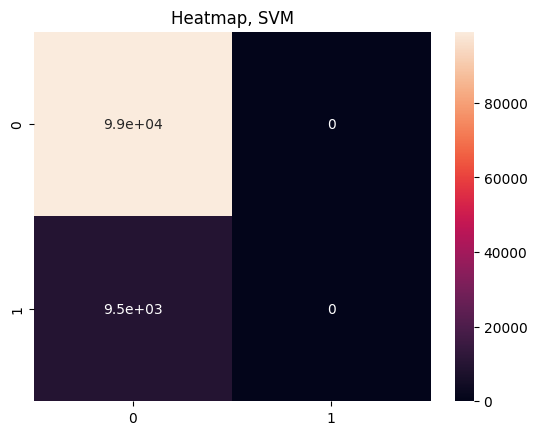

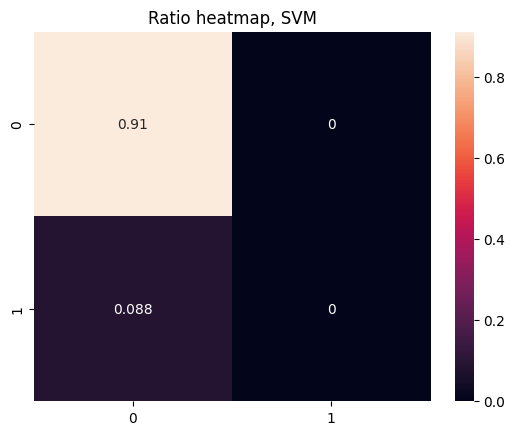

In [152]:
#Confusion matrix
cm = confusion_matrix(y_te, y_te_pred_svm)

#Heatmap
sns.heatmap(cm, annot=True)
plt.title("Heatmap, SVM")
plt.show()

#Percentage confusion matrix
cm_ratio = cm/len(y_te)

#Heatmap
sns.heatmap(cm_ratio, annot=True)
plt.title("Ratio heatmap, SVM")
plt.show()